In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import (
    start_scope, seed, defaultclock, TimedArray, NeuronGroup, Synapses,
    PoissonInput, StateMonitor, SpikeMonitor, Network, collect,
    ms, second, Hz, mV, pF, uS, nS, nA, amp, siemens, volt
)

DT = 0.02 * ms
RECORD_DT = 0.2 * ms

Cm = 200 * pF
gNa = 24 * uS
gK = 7.2 * uS
gL = 60 * nS

ENa = 50 * mV
EK = -77 * mV
EL = -54.4 * mV

E_AMPA = 0 * mV
E_GABA = -80 * mV

tau_AMPA = 3.0 * ms
tau_GABA = 12.0 * ms

w_EI = 100 * nS
w_IE = 200 * nS

I_TONIC_E = 2.0 * nA
I_TONIC_I = 1.0 * nA


BG_N = 200
BG_RATE = 2 * Hz
BG_WEIGHT = 0.5 * nS

PULSE_WIDTH = 0.06 * ms     # 60 us
SETTLE = 2.0 * second
SEGMENT = 4.0 * second
AMP_LEVELS_MA = np.arange(0.0, 11.0, 1.0)

DBS_GAIN_NA_PER_MA = 10.0
DBS_TARGET = np.array([1.0, 0.0])

eqs = r"""
dv/dt = (
      gNa*m**3*h*(ENa-v)
    + gK*n**4*(EK-v)
    + gL*(EL-v)
    + gA*(E_AMPA-v)
    + gG*(E_GABA-v)
    + I_tonic
    + I_dbs
    )/Cm : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dgA/dt = -gA/tau_AMPA : siemens
dgG/dt = -gG/tau_GABA : siemens

I_tonic : amp
dbs_target : 1

I_dbs = dbs_target * stim_ta(t) : amp
"""


def build_stimulus(freq_hz, dt=DT):

    dt_s = float(dt / second)
    settle_s = float(SETTLE / second)
    seg_s = float(SEGMENT / second)
    pw_s = float(PULSE_WIDTH / second)

    n_settle = int(round(settle_s / dt_s))
    n_seg = int(round(seg_s / dt_s))
    n_total = n_settle + len(AMP_LEVELS_MA) * n_seg

    stim_nA = np.zeros(n_total, dtype=float)
    amp_trace_mA = np.zeros(n_total, dtype=float)

    period_s = 1.0 / float(freq_hz)

    for j, amp_mA in enumerate(AMP_LEVELS_MA):
        i0 = n_settle + j * n_seg
        i1 = i0 + n_seg

        local_t = np.arange(n_seg) * dt_s
        pulse = np.mod(local_t, period_s) < pw_s

        stim_nA[i0:i1] = (
            float(amp_mA) * DBS_GAIN_NA_PER_MA * pulse.astype(float)
        )
        amp_trace_mA[i0:i1] = amp_mA

    stim_ta = TimedArray(stim_nA * nA, dt=dt)
    total_time = n_total * dt

    return stim_ta, total_time, amp_trace_mA


#simu
def run_pair(freq_hz=55.0, rng_seed=1):
    start_scope()
    seed(rng_seed)
    defaultclock.dt = DT

    stim_ta, total_time, amp_trace_int = build_stimulus(freq_hz)

    namespace = dict(
        Cm=Cm, gNa=gNa, gK=gK, gL=gL,
        ENa=ENa, EK=EK, EL=EL,
        E_AMPA=E_AMPA, E_GABA=E_GABA,
        tau_AMPA=tau_AMPA, tau_GABA=tau_GABA,
        stim_ta=stim_ta,
    )

    G = NeuronGroup(
        2,
        eqs,
        threshold="v > 0*mV",
        refractory="v > -20*mV",
        method="rk4",
        namespace=namespace,
    )

    # 0 = excitatory, 1 = inhibitory
    G.v = -65 * mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318
    G.gA = 0 * nS
    G.gG = 0 * nS
    G.I_tonic = [I_TONIC_E, I_TONIC_I]
    G.dbs_target = DBS_TARGET

    # E -> I
    S_EI = Synapses(G, G, on_pre="gA_post += w_EI",
                    namespace={"w_EI": w_EI})
    S_EI.connect(i=0, j=1)

    # I -> E
    S_IE = Synapses(G, G, on_pre="gG_post += w_IE",
                    namespace={"w_IE": w_IE})
    S_IE.connect(i=1, j=0)

    # Independent excitatory background bombardment to each cell.
    P_bg = PoissonInput(
        G, "gA",
        N=BG_N,
        rate=BG_RATE,
        weight=BG_WEIGHT,
    )

    M = StateMonitor(
        G, ["v", "gA", "gG", "h", "I_dbs"],
        record=True,
        dt=RECORD_DT,
    )
    Sp = SpikeMonitor(G)

    net = Network(collect())
    net.run(total_time, report="text")

    # Neural-only LFP proxy: total synaptic current onto the E cell.
    # Direct DBS current is intentionally NOT included here.
    I_syn_E = (
        M.gA[0] * (E_AMPA - M.v[0])
        + M.gG[0] * (E_GABA - M.v[0])
    )
    lfp_neural = -np.asarray(I_syn_E / nA)

    return {
        "freq_hz": float(freq_hz),
        "t_s": np.asarray(M.t / second),
        "vE_mV": np.asarray(M.v[0] / mV),
        "vI_mV": np.asarray(M.v[1] / mV),
        "hE": np.asarray(M.h[0]),
        "lfp_neural": lfp_neural,
        "spike_t_s": np.asarray(Sp.t / second),
        "spike_i": np.asarray(Sp.i),
    }






In [2]:
def amplitude_at_time(t_s):
    """Clinical amplitude label for every time sample."""
    settle_s = float(SETTLE / second)
    seg_s = float(SEGMENT / second)

    out = np.zeros_like(t_s, dtype=float)
    post = t_s >= settle_s

    j = np.floor((t_s[post] - settle_s) / seg_s).astype(int)
    j = np.clip(j, 0, len(AMP_LEVELS_MA) - 1)
    out[post] = AMP_LEVELS_MA[j]
    return out


def segment_bounds(amp_mA):
    settle_s = float(SETTLE / second)
    seg_s = float(SEGMENT / second)
    j = int(np.where(AMP_LEVELS_MA == amp_mA)[0][0])
    return settle_s + j * seg_s, settle_s + (j + 1) * seg_s


def summarize_protocol(result, discard_s=0.5):
    """Print dominant frequency, beta/gamma power and saturation metrics."""
    fs = 1.0 / float(RECORD_DT / second)

    print("\nAmplitude summary")
    print("mA   peak_Hz   betaP      gammaP     E_rate_Hz  meanV_mV  mean_h")

    for amp_mA in AMP_LEVELS_MA:
        t0, t1 = segment_bounds(amp_mA)
        t0 += discard_s

        mask = (result["t_s"] >= t0) & (result["t_s"] < t1)
        x = result["lfp_neural"][mask]
        x = x - np.mean(x)

        nper = min(len(x), int(2.0 * fs))
        f, pxx = signal.welch(x, fs=fs, nperseg=nper)

        useful = (f >= 5) & (f <= 150)
        peak_hz = f[useful][np.argmax(pxx[useful])]

        beta = (f >= 13) & (f <= 30)
        gamma = (f >= 30) & (f <= 100)
        beta_p = np.trapz(pxx[beta], f[beta])
        gamma_p = np.trapz(pxx[gamma], f[gamma])

        spmask = (
            (result["spike_i"] == 0)
            & (result["spike_t_s"] >= t0)
            & (result["spike_t_s"] < t1)
        )
        rate = np.sum(spmask) / (t1 - t0)

        mean_v = np.mean(result["vE_mV"][mask])
        mean_h = np.mean(result["hE"][mask])

        print(
            f"{amp_mA:>2.0f}   {peak_hz:>7.2f}  "
            f"{beta_p:>9.3g}  {gamma_p:>9.3g}  "
            f"{rate:>9.2f}  {mean_v:>8.2f}  {mean_h:>6.3f}"
        )


def make_period2_artifact(result, alternation=0.20, tau_ms=1.5):
    """Toy recording artifact with alternating pulse amplitudes.

    Why this model is useful:
    If every other stimulation artifact is slightly different, the
    artifact repeats every TWO DBS periods.  A 55-Hz pulse train then
    has spectral components at multiples of 27.5 Hz:
        27.5, 55, 82.5, 110, ...
    So a 28-Hz + 55-Hz + 83-Hz pattern can arise without neural dynamics.

    This is only a diagnostic toy model, not a claim about the device.
    """
    t = result["t_s"]
    dt = float(RECORD_DT / second)
    fs = 1.0 / dt
    fstim = result["freq_hz"]
    amps = amplitude_at_time(t)

    impulses = np.zeros_like(t)
    settle_s = float(SETTLE / second)
    seg_s = float(SEGMENT / second)

    global_pulse_index = 0
    for amp_mA in AMP_LEVELS_MA:
        if amp_mA == 0:
            continue

        t0, t1 = segment_bounds(amp_mA)
        pulse_times = np.arange(t0, t1, 1.0 / fstim)

        for tp in pulse_times:
            k = int(np.argmin(np.abs(t - tp)))
            alt = 1.0 + alternation * ((-1.0) ** global_pulse_index)
            impulses[k] += amp_mA * alt
            global_pulse_index += 1

    # Simple exponential artifact decay / amplifier ringing envelope.
    a = np.exp(-dt / (tau_ms * 1e-3))
    artifact = signal.lfilter([1.0], [1.0, -a], impulses)

    # Remove slow amplitude trend and normalize for visual comparison.
    artifact = signal.detrend(artifact)
    sd = np.std(artifact)
    if sd > 0:
        artifact = artifact / sd

    return artifact


def plot_spectrogram(result, x, title, fmax=150):
    fs = 1.0 / float(RECORD_DT / second)

    nper = int(1.5 * fs)
    nover = int(1.3 * fs)

    f, tt, Sxx = signal.spectrogram(
        x - np.mean(x),
        fs=fs,
        nperseg=nper,
        noverlap=nover,
        detrend="constant",
        scaling="density",
        mode="psd",
    )

    keep = (f >= 5) & (f <= fmax)
    Sdb = 10 * np.log10(Sxx[keep] + 1e-18)

    plt.figure(figsize=(12, 5))
    plt.pcolormesh(tt, f[keep], Sdb, shading="auto")
    plt.colorbar(label="Power (dB, arbitrary)")
    plt.ylabel("Frequency (Hz)")
    plt.xlabel("Time (s)")
    plt.title(title)

    # Frequencies of special interest.
    fs0 = result["freq_hz"]
    for y, lab in [
        (0.5 * fs0, "f/2"),
        (fs0, "f"),
        (1.5 * fs0, "3f/2"),
    ]:
        if y <= fmax:
            plt.axhline(y, linestyle="--", linewidth=1, label=f"{lab} = {y:.1f} Hz")

    # Mark amplitude transitions.
    settle_s = float(SETTLE / second)
    seg_s = float(SEGMENT / second)
    for j in range(len(AMP_LEVELS_MA) + 1):
        plt.axvline(settle_s + j * seg_s, linewidth=0.5, alpha=0.4)

    plt.legend(loc="upper right")
    plt.tight_layout()


def plot_state_summary(result):
    t = result["t_s"]
    amp = amplitude_at_time(t)

    fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    ax[0].plot(t, result["vE_mV"], linewidth=0.5)
    ax[0].set_ylabel("E V (mV)")

    ax[1].plot(t, result["hE"], linewidth=0.8)
    ax[1].set_ylabel("Na h")
    ax[1].set_ylim(0, 1)

    ax[2].plot(t, amp, linewidth=1.2)
    ax[2].set_ylabel("DBS amplitude\n(label, mA)")
    ax[2].set_xlabel("Time (s)")

    fig.suptitle(
        f"HH state variables during {result['freq_hz']:.0f}-Hz DBS\n"
        "Depolarization block would usually show reduced spiking, "
        "sustained depolarization, and low h"
    )
    plt.tight_layout()


Starting simulation at t=0. s for a duration of 46. s
12.63382 s (27%) simulated in 10s, estimated 26s remaining.
24.91676 s (54%) simulated in 20s, estimated 17s remaining.
36.8246 s (80%) simulated in 30s, estimated 7s remaining.
46. s (100%) simulated in 37s

Amplitude summary
mA   peak_Hz   betaP      gammaP     E_rate_Hz  meanV_mV  mean_h
 0      6.00       0.14      0.163      19.14    -59.25   0.407
 1     55.00      0.121      0.605      34.57    -59.10   0.410
 2    110.00    0.00176       1.83      54.86    -58.82   0.410
 3    110.00    0.00197        1.9      54.86    -58.86   0.411
 4    110.00    0.00154        1.9      54.86    -58.88   0.412
 5    110.00    0.00227       1.91      54.86    -58.90   0.412
 6    110.00    0.00138       1.94      54.86    -58.91   0.412
 7    110.00    0.00206       1.95      54.86    -58.93   0.412
 8    110.00    0.00137       1.99      54.86    -58.94   0.412
 9    110.00    0.00161       1.98      54.86    -58.94   0.412
10    110.00  

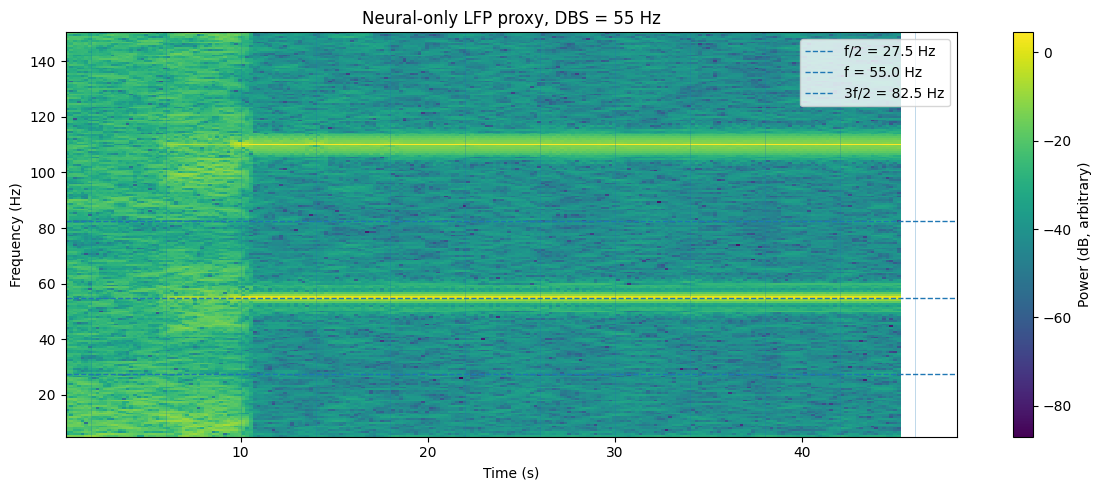

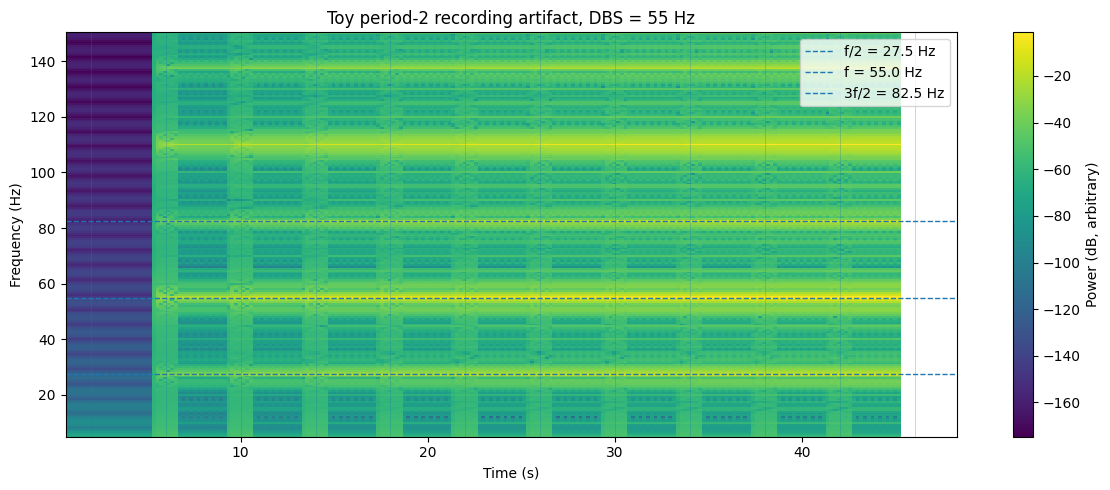

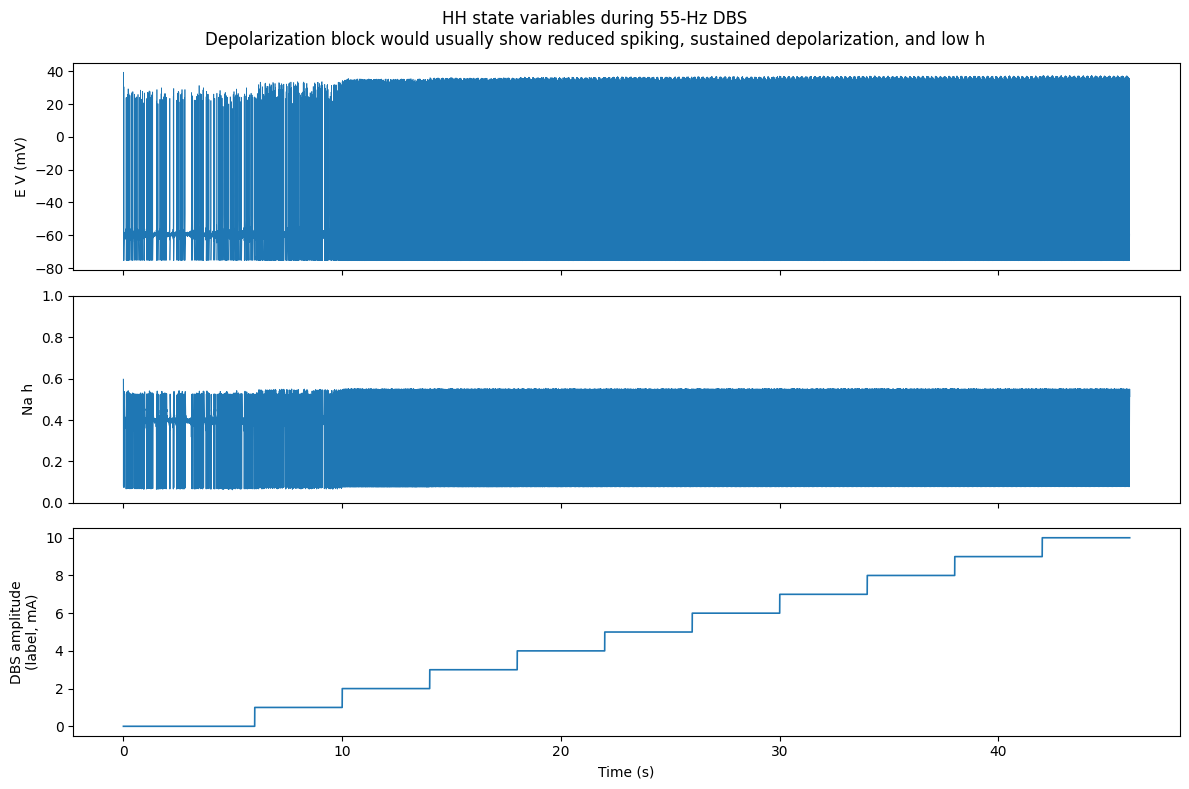

In [ ]:
#55.0, 80.0
fstim=55.0
result = run_pair(freq_hz=fstim, rng_seed=1)

summarize_protocol(result)


plot_spectrogram(
    result,
    result["lfp_neural"],
    title=f"Neural-only LFP proxy, DBS = {fstim:.0f} Hz",
)

# Artifact-only alternative: period-2 pulse asymmetry.
artifact = make_period2_artifact(result, alternation=0.20)
plot_spectrogram(
    result,
    artifact,
    title=f"Toy period-2 recording artifact, DBS = {fstim:.0f} Hz",
)

plot_state_summary(result)

plt.show()
